# Лабораторная работа 4. Визуальный анализ.

1. Скачайте этот ноутбук к себе.
2. Заполните пропущенные ячейки, отвечая на заданные вопросы. Там должен быть код! (если не сказано обратное)
3. Сохраните результат в своём репозитории.

#### Полезная литература

- [Галерея графиков Matplotlib](https://matplotlib.org/gallery/index.html)
- [Галерея графиков Seaborn](http://seaborn.pydata.org/examples/index.html)
- [Открытый курс машинного обучения. Тема 2: Визуализация данных c Python](https://habr.com/company/ods/blog/323210/)

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
colab = False # работаю на своём компьютере
if colab:
    from google.colab import drive
    drive.mount('/content/drive')

## Визуальный анализ данных

В этом задании вам предлагается провести визуальный анализ датасета результатов экзаменов студентов  https://www.kaggle.com/spscientist/students-performance-in-exams. 

In [39]:
if colab:
    df = pd.read_csv('/content/drive/My Drive/Data/StudentsPerformance.csv')
else:
    df = pd.read_csv("StudentsPerformance.csv")

df

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


## Задания
#### 1. Постройте 3 графика, показывающих распределение результатов экзаменов (каждый график на предмет).


Графики должны быть в одном ряду и у них должен быть общий заголовок "Результаты экзаменов".

Для результатов каждого экзамена посчитайте медианные значения.


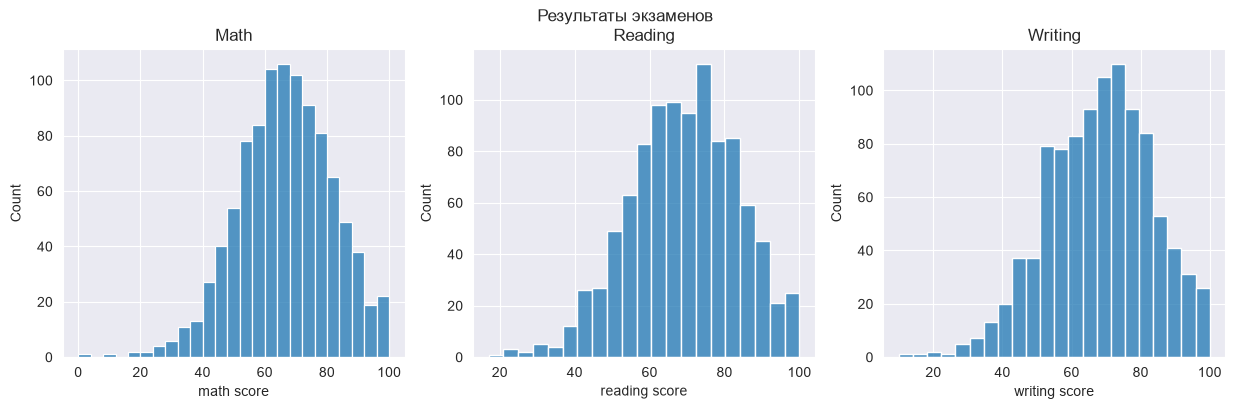

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Результаты экзаменов")

sns.histplot(df['math score'], ax=axes[0])
axes[0].set_title('Math')

sns.histplot(df['reading score'], ax=axes[1])
axes[1].set_title('Reading')

sns.histplot(df['writing score'], ax=axes[2])
axes[2].set_title('Writing')

plt.show()

In [41]:
print('Median math score:', df['math score'].median())
print('Median reading score:', df['reading score'].median())
print('Median writing score:', df['writing score'].median())

Median math score: 66.0
Median reading score: 70.0
Median writing score: 69.0


#### 2. Образование родителей
Какие уровни образование есть в столбце *'parental level of education'* и сколько строк в датафрейме соответствует каждому уровню? 

Постройте график и ответьте на вопрос ниже

Отличаются ли баллы по математике у детей с разным образованием родителей?
Постройте график, где по оси Х находятся уровни образования родителей, а по У - баллы по математике.


parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64


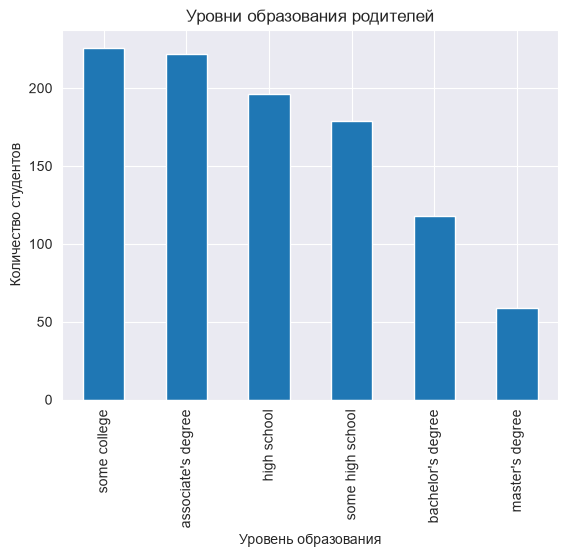

In [42]:
education_counts = df['parental level of education'].value_counts()
print(education_counts)

education_counts.plot(kind='bar')
plt.title('Уровни образования родителей')
plt.xlabel('Уровень образования')
plt.ylabel('Количество студентов')
plt.show()

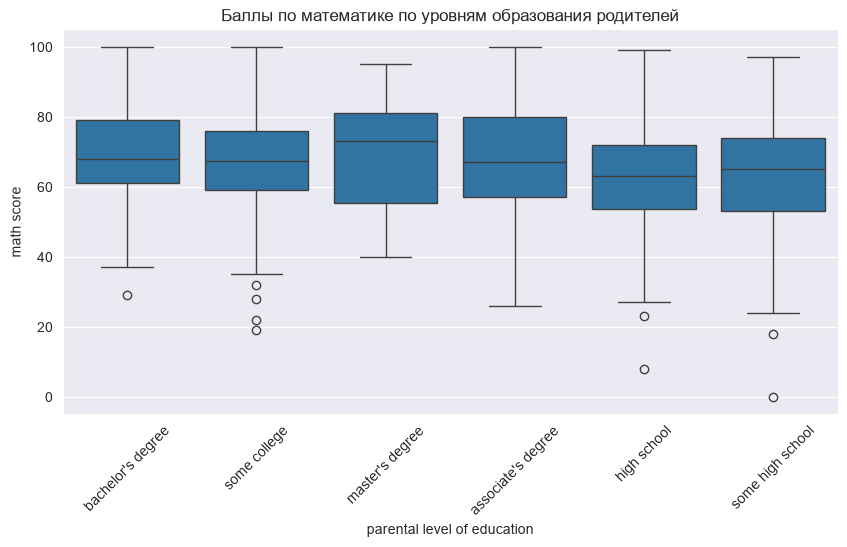

In [43]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='parental level of education', y='math score', data=df)
plt.title('Баллы по математике по уровням образования родителей')
plt.xticks(rotation=45)
plt.show()

# Ответ на вопрос: да, баллы отличаются. Судя по графику (медиана - линия внутри коробки),
# самая высокая медиана балла по математике у родителей со степенью master's degree,
# самая низкая - у родителей со средним образованием (high school)

#### 3. Выведите число студенток, набравших больше 90 баллов по всем предметам.


In [44]:
high_scoring_female_count = df[
    (df['gender'] == 'female') &
    (df['math score'] > 90) &
    (df['reading score'] > 90) &
    (df['writing score'] > 90)
].shape[0]

print('Студенток с баллом выше 90 по всем предметам:', high_scoring_female_count)

Студенток с баллом выше 90 по всем предметам: 17


#### 4. Сравните баллы у студентов разных полов. Используя agg() выведите минимальное, максимальное и медианное значение
 

In [45]:
gender_stats = df.groupby('gender').agg(
    math_min=('math score', 'min'),
    math_max=('math score', 'max'),
    math_median=('math score', 'median'),
    reading_min=('reading score', 'min'),
    reading_max=('reading score', 'max'),
    reading_median=('reading score', 'median'),
    writing_min=('writing score', 'min'),
    writing_max=('writing score', 'max'),
    writing_median=('writing score', 'median'),
)

print(gender_stats)

        math_min  math_max  math_median  reading_min  reading_max  \
gender                                                              
female         0       100         65.0           17          100   
male          27       100         69.0           23          100   

        reading_median  writing_min  writing_max  writing_median  
gender                                                            
female            73.0           10          100            74.0  
male              66.0           15          100            64.0  


#### 5. Выясните, влияет ли обед и подготовка к тесту на средний балл студентов разного пола 
###### (подсказка: используете agg())

In [46]:
lunch_stats = df.groupby(['gender', 'lunch']).agg(
    math_mean=('math score', 'mean'),
    reading_mean=('reading score', 'mean'),
    writing_mean=('writing score', 'mean'),
)
print(lunch_stats)

prep_stats = df.groupby(['gender', 'test preparation course']).agg(
    math_mean=('math score', 'mean'),
    reading_mean=('reading score', 'mean'),
    writing_mean=('writing score', 'mean'),
)
print(prep_stats)

                     math_mean  reading_mean  writing_mean
gender lunch                                              
female free/reduced  55.814815     67.386243     66.444444
       standard      68.124620     75.607903     75.927052
male   free/reduced  62.457831     61.542169     59.126506
       standard      72.022152     67.537975     65.509494
                                math_mean  reading_mean  writing_mean
gender test preparation course                                       
female completed                67.195652     77.375000     78.793478
       none                     61.670659     69.982036     68.982036
male   completed                72.339080     70.212644     69.793103
       none                     66.688312     62.795455     59.649351


#### 6. Постройте график, показывающий зависимость уровня образования родителей от их расы 

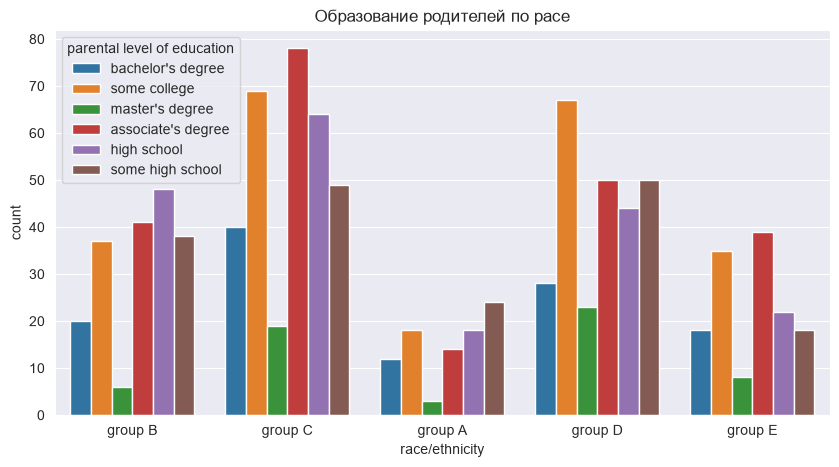

In [47]:
plt.figure(figsize=(10, 5))
sns.countplot(x='race/ethnicity', hue='parental level of education', data=df)
plt.title('Образование родителей по расе')
plt.show()

#### 7. Постройте график, показывающий зависимость прохождения подготовительного теста от уровня образования родителей.


Кто чаще ходит на курсы: дети, родители которых закончили только старшую школу, или дети, чьи родители получили степень бакалавра\магистра?

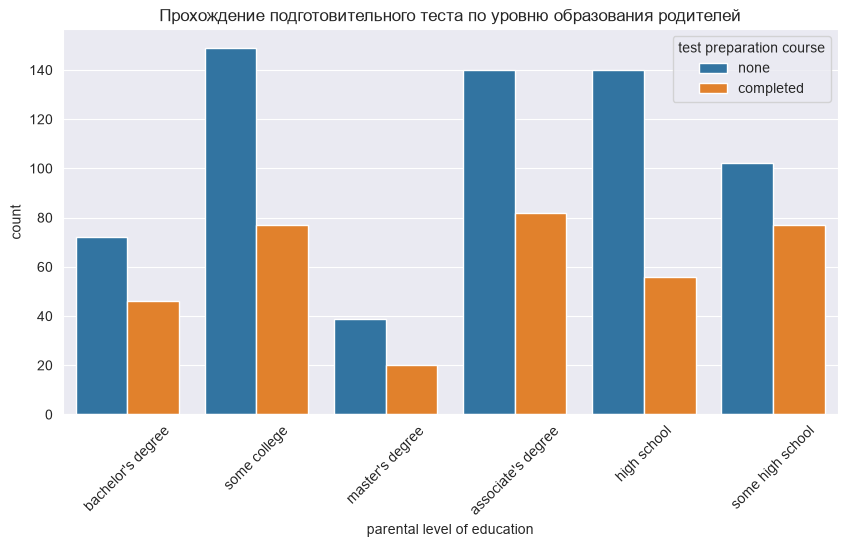

test preparation course
none         140
completed     56
Name: count, dtype: int64
test preparation course
none         111
completed     66
Name: count, dtype: int64
Доля прошедших подготовку (high school): 0.29
Доля прошедших подготовку (bachelor/master): 0.37


In [48]:
plt.figure(figsize=(10, 5))
sns.countplot(x='parental level of education', hue='test preparation course', data=df)
plt.title('Прохождение подготовительного теста по уровню образования родителей')
plt.xticks(rotation=45)
plt.show()

# для расчёта вывода: сравниваем долю прошедших подготовку (completed),
# а не абсолютное число, так как группы разного размера
prep_counts_high_school = df[df['parental level of education'] == 'high school']['test preparation course'].value_counts()
prep_counts_higher_education = df[df['parental level of education'].isin(["bachelor's degree", "master's degree"])]['test preparation course'].value_counts()

print(prep_counts_high_school)
print(prep_counts_higher_education)

share_completed_high_school = prep_counts_high_school['completed'] / prep_counts_high_school.sum()
share_completed_higher_education = prep_counts_higher_education['completed'] / prep_counts_higher_education.sum()

print('Доля прошедших подготовку (high school):', round(share_completed_high_school, 2))
print('Доля прошедших подготовку (bachelor/master):', round(share_completed_higher_education, 2))

# Вывод: доля прошедших подготовку выше у родителей со степенью bachelor's/master's degree
# (0.37 против 0.29 у high school), значит их дети чаще ходят на курсы

#### 8. Постройте plot.pie, показывающий, сколько людей сдали\не сдали экзамен по математике.

Сдавшим считается человек, набравший 40 баллов.

###### Подсказка: создайте столбец в датафрейме, который содержит результат сдачи (сдал или не сдал)

math pass status
passed    960
failed     40
Name: count, dtype: int64


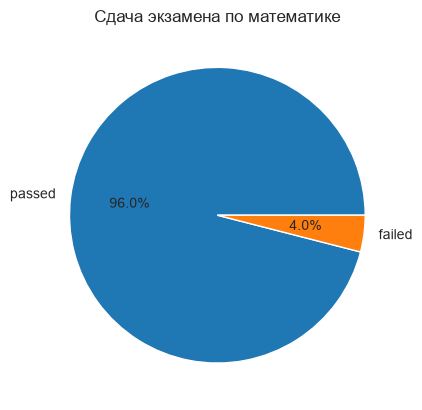

In [49]:
df['math pass status'] = df['math score'].apply(lambda score: 'passed' if score >= 40 else 'failed')

print(df['math pass status'].value_counts())

df['math pass status'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title('Сдача экзамена по математике')
plt.ylabel('')
plt.show()

#### 9. Постройте plot.pie, показывающий распределение студентов по оценкам

Оценки студентов выставляются по шкале:<br>
0  - 40 marks : grade E<br>
41 - 60 marks : grade D<br>
60 - 70 marks : grade C<br>
70 - 80 marks : grade B<br>
80 - 90 marks : grade A<br>
90 - 100 marks : grade O<br>

Для этого посчитайте сумму результатов за 3 экзамена и найдите среднее. Оценка выставляется по среднему значению. Если студент не сдал математику(даже если средний балл выше 40), он получает Е

grade
B    261
C    256
D    237
A    146
O     52
E     48
Name: count, dtype: int64


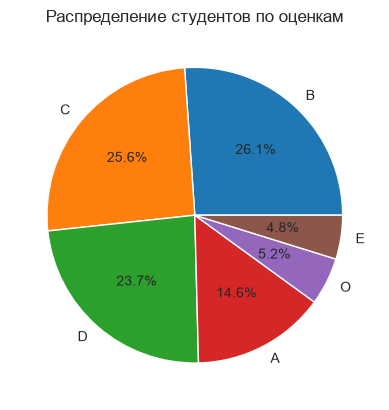

In [50]:
def get_grade(row):
    if row['math score'] < 40:
        return 'E'
    average_score = (row['math score'] + row['reading score'] + row['writing score']) / 3
    if average_score >= 90:
        return 'O'
    elif average_score >= 80:
        return 'A'
    elif average_score >= 70:
        return 'B'
    elif average_score >= 60:
        return 'C'
    elif average_score >= 41:
        return 'D'
    else:
        return 'E'

df['grade'] = df.apply(get_grade, axis=1)

print(df['grade'].value_counts())

df['grade'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title('Распределение студентов по оценкам')
plt.ylabel('')
plt.show()

#### 10. Постройте countplot, показывающий зависимость между итоговой оценкой студентов и его полом. Студенты какого пола получили больше оценок О, А, В

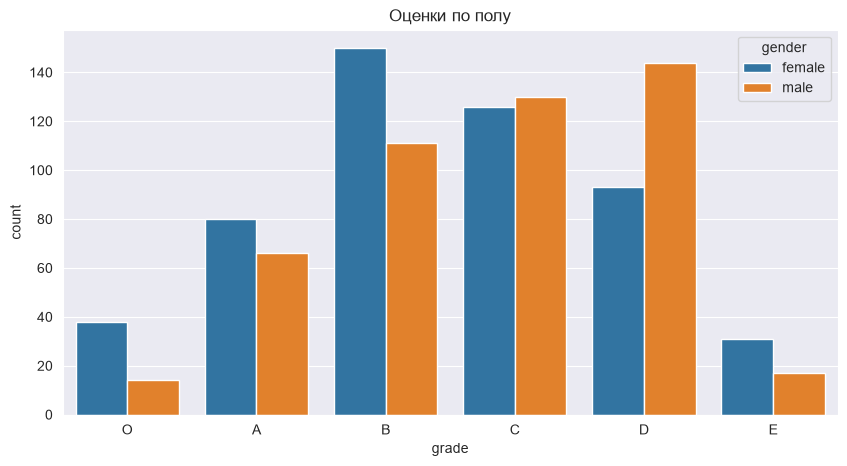

gender
female    268
male      191
Name: grade, dtype: int64
gender  female  male
grade               
O           38    14
A           80    66
B          150   111


In [51]:
plt.figure(figsize=(10, 5))
sns.countplot(x='grade', hue='gender', data=df, order=['O', 'A', 'B', 'C', 'D', 'E'])
plt.title('Оценки по полу')
plt.show()

print(df[df['grade'].isin(['O', 'A', 'B'])].groupby('gender')['grade'].count())

# для расчёта вывода: считаем количество каждой оценки отдельно по полу
grade_by_gender = pd.crosstab(df['grade'], df['gender'])
print(grade_by_gender.loc[['O', 'A', 'B']])

# Вывод: по всем трём оценкам (O, A, B) количество девушек больше, чем юношей,
# значит девушки получили больше оценок O, A и B